# Atividade 2: Busca e ranking de conceitos em anúncios com CLIP

**Aluno:** Anderson Corrêa

**Objetivo:** usar o CLIP pré-treinado (ViT-B/32), sem nenhum treino, para duas tarefas sobre o corpus ADS-16: (1) ordenar conceitos pela frequência com que aparecem nas imagens e (2) buscar imagens a partir de uma frase.

**Requisitos de execução**

- Ambiente: Google Colab com GPU T4
- Memória de GPU: cerca de 0,8 GB (medido na T4)
- Memória RAM: cerca de 2 GB (processo principal, medido na T4)
- Disco: 3 GB livres
- Tempo estimado: cerca de 3 minutos (medido na T4, sem contar a inicialização da máquina; o download de 0,8 GB pode variar)

**Como executar:** menu *Ambiente de execução*, *Executar tudo*. O notebook baixa os dados sozinho e não precisa de login. A biblioteca `transformers` já vem instalada no Colab. Os embeddings das imagens ficam em disco, então uma segunda execução na mesma sessão não os calcula de novo.

## Código de apoio

As células abaixo definem as funções usadas no restante do notebook: execução e cronômetro, dados, CLIP e gráficos.

In [ ]:
"""Run setup and saving shared by the notebooks.

A run seeds the random generators, keeps its figures in one folder and ends
by writing its metrics and packing everything into one archive. The archive
layout is the contract with the script that collects the outputs of a Colab
run: ``metrics.json`` at the top level and the PNG files under ``figures/``.
"""

import json
import random
import sys
from contextlib import contextmanager
from dataclasses import dataclass
from pathlib import Path
from resource import RUSAGE_SELF, getrusage
from time import monotonic
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import torch

BYTES_PER_MEGABYTE = 1e6


class Stopwatch:
    """Measures how long the named steps of a run take.

    ``seconds`` maps every finished step to its duration, in the order the
    steps ran, ready to be saved with the metrics. Each step is also printed
    when it ends, so the cost of a notebook is visible while it runs.
    """

    def __init__(self) -> None:
        """Starts with no step measured."""
        self.seconds = {}

    @contextmanager
    def measure(self, name: str):
        """Times the body of a ``with`` block and records it under ``name``.

        A block that raises is not recorded.
        """
        started_at = monotonic()
        yield
        self.seconds[name] = round(monotonic() - started_at, 1)
        print(f"{name}: {self.seconds[name]} s")


@dataclass(frozen=True)
class Run:
    """One notebook run: its activity, its output folders and when it started.

    ``started_at`` is a reading of the monotonic clock, good only for
    measuring elapsed time.
    """

    activity: str
    output_dir: Path
    figures_dir: Path
    started_at: float


def seed_everything(seed: int) -> None:
    """Seeds the random generators of Python, numpy and torch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def start_run(activity: str) -> Run:
    """Prepares the output folders of an activity and starts its timer.

    Creates ``outputs/<activity>/figures`` under the current directory. The
    peak GPU memory counter is reset when CUDA is available, so the peak saved
    later belongs to this run only.
    """
    output_dir = Path("outputs") / activity
    figures_dir = output_dir / "figures"
    figures_dir.mkdir(parents=True, exist_ok=True)
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    return Run(activity, output_dir, figures_dir, monotonic())


def peak_gpu_memory_mb() -> float:
    """Returns the peak memory allocated by PyTorch on the GPU, or 0.0 without CUDA."""
    if not torch.cuda.is_available():
        return 0.0
    return torch.cuda.max_memory_allocated() / BYTES_PER_MEGABYTE


def peak_ram_mb() -> float:
    """Returns the peak resident memory of the main process, in megabytes.

    Data loader worker processes are not included. The operating system
    reports the value in kilobytes on Linux and in bytes on macOS.
    """
    peak = getrusage(RUSAGE_SELF).ru_maxrss
    peak_bytes = peak if sys.platform == "darwin" else peak * 1024
    return peak_bytes / BYTES_PER_MEGABYTE


def save_run(run: Run, metrics: dict) -> Path:
    """Writes the metrics of a run and packs them with its figures.

    A copy of ``metrics`` gains ``runtime_seconds``, ``peak_gpu_memory_mb``
    and ``peak_ram_mb`` and is written to ``outputs/<activity>/metrics.json``.
    The archive ``outputs_<activity>.zip`` is created in the current directory
    and its path is returned.
    """
    saved = {
        **metrics,
        "runtime_seconds": round(monotonic() - run.started_at, 1),
        "peak_gpu_memory_mb": round(peak_gpu_memory_mb(), 1),
        "peak_ram_mb": round(peak_ram_mb(), 1),
    }
    metrics_path = run.output_dir / "metrics.json"
    metrics_path.write_text(json.dumps(saved, indent=2, ensure_ascii=False), encoding="utf-8")
    archive = Path(f"outputs_{run.activity}.zip")
    with ZipFile(archive, "w", ZIP_DEFLATED) as bundle:
        bundle.write(metrics_path, "metrics.json")
        for figure in sorted(run.figures_dir.glob("*.png")):
            bundle.write(figure, f"figures/{figure.name}")
    return archive


In [ ]:
"""Dataset download, image discovery, splitting and preprocessing shared by the notebooks."""

from collections import Counter
from hashlib import sha256
from pathlib import Path
from zipfile import ZipFile

import torch
from PIL import Image
from requests import get
from sklearn.model_selection import train_test_split
from torch import Tensor
from torch.nn.functional import pad
from torch.utils.data import Dataset
from torchvision.transforms import CenterCrop, Compose, Normalize, Resize, ToTensor

KAGGLE_DOWNLOAD_URL = "https://www.kaggle.com/api/v1/datasets/download/{slug}"
IMAGE_SUFFIXES = {".bmp", ".jpg", ".jpeg", ".png"}
MINIMUM_IMAGES_PER_CLASS = 7
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def download_kaggle_dataset(slug: str, destination: Path) -> Path:
    """Downloads and extracts a public Kaggle dataset, once.

    A marker file records a finished download, so calling this again for the
    same destination returns immediately. No Kaggle account is needed.
    """
    destination = Path(destination)
    marker = destination / ".complete"
    if marker.exists():
        return destination
    destination.mkdir(parents=True, exist_ok=True)
    archive = destination / "archive.zip"
    with get(KAGGLE_DOWNLOAD_URL.format(slug=slug), stream=True, timeout=60) as response:
        response.raise_for_status()
        with open(archive, "wb") as handle:
            for chunk in response.iter_content(chunk_size=1 << 20):
                handle.write(chunk)
    with ZipFile(archive) as bundle:
        bundle.extractall(destination)
    archive.unlink()
    marker.touch()
    return destination


def has_image_name(path: Path) -> bool:
    """Tells whether a path is named like a visible image file."""
    return not path.name.startswith(".") and path.suffix.lower() in IMAGE_SUFFIXES


def count_image_files(root: Path) -> int:
    """Counts the visible files under root that are named like images.

    Nothing is opened, so exact copies and files that cannot be decoded are
    counted too. This is the size of a download before any cleaning.
    """
    return sum(1 for path in Path(root).rglob("*") if path.is_file() and has_image_name(path))


def is_readable_image(path: Path) -> bool:
    """Tells whether a file is a visible image that Pillow can decode."""
    if not has_image_name(path):
        return False
    try:
        with Image.open(path) as image:
            image.load()
    except (OSError, SyntaxError, ValueError):
        return False
    return True


def load_rgb_on_white(path: Path) -> Image.Image:
    """Opens an image as RGB, showing transparent pixels as white.

    Converting a transparent PNG straight to RGB keeps whatever colour sits
    under the transparent pixels, usually black, so logos on transparent
    backgrounds turn into black squares. Compositing on white shows them as
    a viewer would.
    """
    with Image.open(path) as image:
        rgba = image.convert("RGBA")
    background = Image.new("RGBA", rgba.size, (255, 255, 255, 255))
    return Image.alpha_composite(background, rgba).convert("RGB")


def file_digest(path: Path) -> str:
    """Returns the SHA-256 hash of a file's bytes."""
    return sha256(path.read_bytes()).hexdigest()


def list_image_folder(root: Path) -> tuple[list[Path], list[int], list[str]]:
    """Finds every readable image under root and labels it by its parent folder.

    Returns the image paths, one integer label per path, and the class names
    in the order used by the labels. Unreadable files are left out. Exact
    copies within one class keep only the first path in sorted order. Files
    with identical content under two or more classes have an ambiguous label,
    so all of them are left out.
    """
    groups = {}
    for path in sorted(path for path in Path(root).rglob("*") if path.is_file() and is_readable_image(path)):
        groups.setdefault(file_digest(path), []).append(path)
    paths = sorted(
        group[0] for group in groups.values() if len({path.parent.name for path in group}) == 1
    )
    class_names = sorted({path.parent.name for path in paths})
    index = {name: position for position, name in enumerate(class_names)}
    labels = [index[path.parent.name] for path in paths]
    return paths, labels, class_names


def stratified_split(
    labels: list[int],
    fractions: tuple[float, float, float] = (0.7, 0.15, 0.15),
    seed: int = 42,
) -> tuple[list[int], list[int], list[int]]:
    """Splits indices into train, validation and test, keeping class shares.

    Raises ValueError naming the class when a class is too small to appear in
    all three parts.
    """
    for label, count in sorted(Counter(labels).items()):
        if count < MINIMUM_IMAGES_PER_CLASS:
            raise ValueError(
                f"class {label} has {count} images; at least {MINIMUM_IMAGES_PER_CLASS} are needed to split"
            )
    indices = list(range(len(labels)))
    train, rest = train_test_split(
        indices, train_size=fractions[0], stratify=labels, random_state=seed
    )
    validation_share = fractions[1] / (fractions[1] + fractions[2])
    validation, test = train_test_split(
        rest,
        train_size=validation_share,
        stratify=[labels[i] for i in rest],
        random_state=seed,
    )
    return sorted(train), sorted(validation), sorted(test)


class ImageListDataset(Dataset):
    """Serves transformed images and labels from parallel lists."""

    def __init__(self, paths: list[Path], labels: list[int], transform):
        """Stores the image paths, their labels and the transform to apply."""
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self) -> int:
        """Returns the number of images."""
        return len(self.paths)

    def __getitem__(self, index: int):
        """Loads one image as RGB and returns it transformed, with its label."""
        with Image.open(self.paths[index]) as image:
            return self.transform(image.convert("RGB")), self.labels[index]


def imagenet_transform(resize_size: int = 232, crop_size: int = 224) -> Compose:
    """Returns the evaluation preprocessing of a backbone pre-trained on ImageNet.

    The short side is resized to ``resize_size``, a centre square of
    ``crop_size`` is cut out and the channels are normalized with the ImageNet
    mean and standard deviation. The defaults are the published preset of the
    ResNet-50 ``IMAGENET1K_V2`` weights. Other weights may use other sizes.
    """
    return Compose(
        [
            Resize(resize_size),
            CenterCrop(crop_size),
            ToTensor(),
            Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ]
    )


def random_crop_flip(images: Tensor, padding: int, generator: torch.Generator) -> Tensor:
    """Shifts and mirrors every image of a batch at random, keeping its size.

    Each image shaped (channels, size, size) is padded with zeros on every
    side, a window of the original size is cut at a random offset, and the
    window is mirrored left to right with probability one half. Every image
    gets its own offset and its own coin. The random numbers are drawn on the
    CPU from ``generator``, so a seed fixes the result on any device.
    """
    count, channels, height, width = images.shape
    device = images.device
    top = torch.randint(0, 2 * padding + 1, (count,), generator=generator).to(device)
    left = torch.randint(0, 2 * padding + 1, (count,), generator=generator).to(device)
    mirrored = (torch.rand(count, generator=generator) < 0.5).to(device)
    rows = top[:, None] + torch.arange(height, device=device)
    forward = left[:, None] + torch.arange(width, device=device)
    backward = left[:, None] + torch.arange(width - 1, -1, -1, device=device)
    columns = torch.where(mirrored[:, None], backward, forward)
    padded = pad(images, (padding, padding, padding, padding))
    return padded[
        torch.arange(count, device=device)[:, None, None, None],
        torch.arange(channels, device=device)[None, :, None, None],
        rows[:, None, :, None],
        columns[:, None, None, :],
    ]


def channel_statistics(images: Tensor) -> tuple[tuple[float, ...], tuple[float, ...]]:
    """Returns the mean and standard deviation of each channel of uint8 images.

    Pixels are scaled to the range 0 to 1 first, which is the scale
    ``TensorBatches`` normalizes on.
    """
    scaled = images.float() / 255
    mean = scaled.mean(dim=(0, 2, 3))
    std = scaled.std(dim=(0, 2, 3), correction=0)
    return tuple(mean.tolist()), tuple(std.tolist())


class TensorBatches:
    """Batches of normalized images served from uint8 tensors held in memory.

    Stands in for a data loader when a whole split fits in memory: iterating
    yields ``(images, labels)`` batches of float images, and every new
    iteration is one epoch. The tensors live on ``device``, so with a GPU no
    data moves between devices during training. Shuffling and augmentation
    (random shift of up to ``padding`` pixels and mirroring) are fixed by
    ``seed`` and change from one epoch to the next.
    """

    def __init__(
        self,
        images: Tensor,
        labels: Tensor,
        batch_size: int,
        mean: tuple[float, ...],
        std: tuple[float, ...],
        augment: bool = False,
        shuffle: bool = False,
        padding: int = 4,
        seed: int = 0,
        device: torch.device | str = "cpu",
    ):
        """Moves the images and labels to the device and stores the batch settings."""
        self.images = images.to(device)
        self.labels = torch.as_tensor(labels, dtype=torch.long).to(device)
        self.batch_size = batch_size
        self.mean = torch.tensor(mean, device=device).view(1, -1, 1, 1)
        self.std = torch.tensor(std, device=device).view(1, -1, 1, 1)
        self.augment = augment
        self.shuffle = shuffle
        self.padding = padding
        self.generator = torch.Generator().manual_seed(seed)

    def __len__(self) -> int:
        """Returns the number of batches in one epoch."""
        return -(-self.images.shape[0] // self.batch_size)

    def __iter__(self):
        """Yields the batches of one epoch."""
        count = self.images.shape[0]
        if self.shuffle:
            order = torch.randperm(count, generator=self.generator).to(self.images.device)
        else:
            order = torch.arange(count, device=self.images.device)
        for start in range(0, count, self.batch_size):
            chosen = order[start : start + self.batch_size]
            images = self.images[chosen]
            if self.augment:
                images = random_crop_flip(images, self.padding, self.generator)
            yield (images.float() / 255 - self.mean) / self.std, self.labels[chosen]


In [ ]:
"""Zero-shot concept ranking and text-to-image search with a pre-trained CLIP model."""

import re
from pathlib import Path

import torch
from torch import Tensor
from transformers import CLIPModel, CLIPProcessor


CLIP_CHECKPOINT = "openai/clip-vit-base-patch32"
THUMBNAIL_NAME = re.compile(r"^(.+)_th_\d+$")


def scan_ads16(root: Path) -> tuple[list[dict], dict]:
    """Walks the ADS-16 archive once and returns the kept entries with the removal counts."""
    root = Path(root)
    readable = []
    for path in sorted(path for path in root.rglob("*") if path.is_file()):
        parts = path.relative_to(root).parts[:-1]
        if "Ads" in parts:
            source = "anuncio"
        elif "Corpus" in parts:
            source = "participante"
        else:
            continue
        if is_readable_image(path):
            readable.append((path, source, file_digest(path)))
    first_path = {}
    for path, _, digest in readable:
        first_path.setdefault(digest, path)
    originals = {(path.parent, path.stem): path for path, _, _ in readable}
    entries = []
    exact_copies = 0
    thumbnails = 0
    for path, source, digest in readable:
        if first_path[digest] != path:
            exact_copies += 1
            continue
        match = THUMBNAIL_NAME.match(path.stem)
        if source == "participante" and match and (path.parent, match.group(1)) in originals:
            thumbnails += 1
            continue
        category = int(path.parent.name) if source == "anuncio" and path.parent.name.isdigit() else None
        entries.append({"path": path, "source": source, "category": category})
    counts = {"files_found": count_image_files(root), "exact_copies": exact_copies, "thumbnails": thumbnails}
    return entries, counts


def list_ads16_images(root: Path) -> list[dict]:
    """Lists the distinct readable images of the ADS-16 archive.

    Files under an ``Ads`` folder are advertisements and carry the integer
    name of their numbered category folder; files under a ``Corpus`` folder
    belong to the participants and have no category. Other files and
    unreadable files are left out. Of a group of exact copies by content the
    first path in sorted order is kept.

    A participant file named ``<name>_th_<number>.<ext>`` is a thumbnail of
    ``<name>.<ext>`` in the same folder. It is left out when that original
    is in the listing, either as itself or through an exact copy that was
    kept. A thumbnail whose original is absent stays. Advertisements are
    never treated as thumbnails. The result is sorted by path.
    """
    return scan_ads16(root)[0]


def count_ads16_files(root: Path) -> dict:
    """Counts what the cleaning of the ADS-16 archive removes.

    Returns ``files_found``, every file named like an image under ``root``
    before any cleaning, ``exact_copies``, the readable files dropped because
    their content repeats an earlier file, and ``thumbnails``, the files
    dropped by the thumbnail rule of ``list_ads16_images``.
    """
    return scan_ads16(root)[1]


def load_clip(device) -> tuple:
    """Loads the pre-trained CLIP ViT-B/32 and its processor, in evaluation mode on ``device``."""
    model = CLIPModel.from_pretrained(CLIP_CHECKPOINT).to(device).eval()
    processor = CLIPProcessor.from_pretrained(CLIP_CHECKPOINT)
    return model, processor


def unit_rows(tensor: Tensor) -> Tensor:
    """Scales every row of a matrix to unit length."""
    return tensor / tensor.norm(dim=-1, keepdim=True).clamp_min(1e-12)


def projected_features(output) -> Tensor:
    """Returns the projected embeddings from a CLIP feature call, whatever the library version returns."""
    return output if isinstance(output, Tensor) else output.pooler_output


@torch.no_grad()
def embed_images(model, processor, paths: list[Path], device, batch_size: int = 64) -> Tensor:
    """Embeds images with CLIP into unit-length float32 rows on the CPU.

    Every file is opened as RGB, transparent pixels shown as white, and processed in batches of ``batch_size``.
    """
    batches = []
    for start in range(0, len(paths), batch_size):
        images = [load_rgb_on_white(path) for path in paths[start : start + batch_size]]
        pixel_values = processor(images=images, return_tensors="pt")["pixel_values"].to(device)
        features = projected_features(model.get_image_features(pixel_values=pixel_values))
        batches.append(unit_rows(features.float()).cpu())
    if not batches:
        return torch.empty(0, 0)
    return torch.cat(batches)


@torch.no_grad()
def embed_texts(model, processor, texts: list[str], device) -> Tensor:
    """Embeds texts with CLIP into unit-length float32 rows on the CPU.

    Texts longer than the tokenizer's limit are truncated, and a warning
    naming each of them is printed.
    """
    limit = processor.tokenizer.model_max_length
    lengths = processor(text=texts, padding=False, truncation=False)["input_ids"]
    for text, ids in zip(texts, lengths):
        if len(ids) > limit:
            shown = text[:60] + ("..." if len(text) > 60 else "")
            print(f"Warning: text truncated to {limit} tokens ({len(ids)} needed): {shown!r}")
    encoded = processor(text=texts, padding=True, truncation=True, return_tensors="pt")
    features = projected_features(
        model.get_text_features(
            input_ids=encoded["input_ids"].to(device),
            attention_mask=encoded["attention_mask"].to(device),
        )
    )
    return unit_rows(features.float()).cpu()


def cached(path: Path, compute, expected_rows: int | None = None) -> Tensor:
    """Loads the tensor stored at ``path``, or calls ``compute()``, saves its result there and returns it.

    When ``expected_rows`` is given and the stored tensor has a different
    number of rows, the file is stale: it is recomputed and overwritten.
    """
    path = Path(path)
    if path.exists():
        stored = torch.load(path)
        if expected_rows is None or stored.shape[0] == expected_rows:
            return stored
    result = compute()
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(result, path)
    return result


def similarity_matrix(image_embeddings: Tensor, text_embeddings: Tensor) -> Tensor:
    """Returns the cosine similarity of every image to every text, shaped (images, texts).

    When either side has no rows the result is an empty matrix of that shape.
    """
    if image_embeddings.shape[0] == 0 or text_embeddings.shape[0] == 0:
        return torch.empty(image_embeddings.shape[0], text_embeddings.shape[0])
    return unit_rows(image_embeddings) @ unit_rows(text_embeddings).T


def concept_probabilities(similarity: Tensor, logit_scale: float = 100.0) -> Tensor:
    """Applies CLIP's zero-shot rule: a softmax over the concepts of each image's scaled similarities."""
    return (similarity * logit_scale).softmax(dim=-1)


def rank_concepts(
    similarity: Tensor, concepts: list[str], threshold: float, logit_scale: float = 100.0
) -> list[dict]:
    """Ranks concepts by how often they are the likely content of an image.

    For each concept the result gives its mean similarity, its mean
    probability, the share of images whose probability for it is at or above
    ``threshold`` (``frequency``) and the number of such images (``count``).
    The list is sorted by frequency, then by mean similarity, largest first.
    """
    probabilities = concept_probabilities(similarity, logit_scale)
    present = probabilities >= threshold
    ranking = [
        {
            "concept": concept,
            "mean_similarity": similarity[:, index].mean().item(),
            "mean_probability": probabilities[:, index].mean().item(),
            "frequency": present[:, index].float().mean().item(),
            "count": int(present[:, index].sum().item()),
        }
        for index, concept in enumerate(concepts)
    ]
    return sorted(ranking, key=lambda row: (row["frequency"], row["mean_similarity"]), reverse=True)


def top_images(similarity: Tensor, concept_index: int, k: int) -> list[int]:
    """Returns the indices of the ``k`` images most similar to one concept, best first."""
    scores = similarity[:, concept_index]
    return scores.topk(min(k, scores.shape[0])).indices.tolist()


def search(query_embedding: Tensor, image_embeddings: Tensor, k: int = 5) -> list[tuple[int, float]]:
    """Finds the ``k`` images most similar to a query embedding.

    Returns ``(index, score)`` pairs, best first, with the cosine similarity
    as the score. Fewer pairs come back when the corpus has fewer images.
    """
    scores = similarity_matrix(image_embeddings, query_embedding.reshape(1, -1))[:, 0]
    best = scores.topk(min(k, scores.shape[0]))
    return list(zip(best.indices.tolist(), best.values.tolist()))


def describe_tokens(tokenizer, texts: list[str]) -> list[dict]:
    """Shows how a tokenizer splits texts, padded to the longest of them.

    Per text: the ``tokens``, the ``input_ids``, the ``attention_mask`` and
    ``padding``, the number of padding positions. Works with any Hugging Face
    tokenizer, such as CLIP's or BERT's.
    """
    encoded = tokenizer(texts, padding=True)
    return [
        {
            "tokens": tokenizer.convert_ids_to_tokens(ids),
            "input_ids": list(ids),
            "attention_mask": list(mask),
            "padding": list(mask).count(0),
        }
        for ids, mask in zip(encoded["input_ids"], encoded["attention_mask"])
    ]


def sample_in_band(values: Tensor, low: float, high: float, count: int, seed: int) -> list[int]:
    """Draws a seeded random sample of the indices whose value lies in ``[low, high)``.

    Returns fewer than ``count`` indices when the band holds fewer values, and
    an empty list when it holds none. The same seed gives the same sample.
    """
    inside = ((values >= low) & (values < high)).nonzero().flatten()
    generator = torch.Generator().manual_seed(seed)
    order = torch.randperm(inside.shape[0], generator=generator)
    return inside[order][:count].tolist()


In [ ]:
"""Plots used by the notebooks and the report. Labels are in Portuguese."""

from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from torch import Tensor
from torch.nn.functional import interpolate



def plot_history(history: dict, path: Path) -> Figure:
    """Draws loss and accuracy per epoch for training and validation."""
    epochs = range(1, len(history["train_loss"]) + 1)
    figure, (loss_axis, accuracy_axis) = plt.subplots(1, 2, figsize=(11, 4))
    loss_axis.plot(epochs, history["train_loss"], marker="o", label="Treino")
    loss_axis.plot(epochs, history["val_loss"], marker="o", label="Validação")
    loss_axis.set_xlabel("Época")
    loss_axis.set_ylabel("Perda")
    loss_axis.legend()
    accuracy_axis.plot(epochs, history["train_accuracy"], marker="o", label="Treino")
    accuracy_axis.plot(epochs, history["val_accuracy"], marker="o", label="Validação")
    accuracy_axis.set_xlabel("Época")
    accuracy_axis.set_ylabel("Acurácia")
    accuracy_axis.legend()
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_confusion(confusion: list[list[int]], class_names: list[str], path: Path) -> Figure:
    """Draws a confusion matrix with true classes on rows."""
    size = max(5, 0.7 * len(class_names))
    figure, axis = plt.subplots(figsize=(size, size))
    axis.imshow(confusion, cmap="Blues")
    positions = range(len(class_names))
    axis.set_xticks(positions, labels=class_names, rotation=45, ha="right")
    axis.set_yticks(positions, labels=class_names)
    axis.set_xlabel("Classe prevista")
    axis.set_ylabel("Classe real")
    limit = max(max(row) for row in confusion) / 2
    for row_index, row in enumerate(confusion):
        for column_index, value in enumerate(row):
            colour = "white" if value > limit else "black"
            axis.text(column_index, row_index, str(value), ha="center", va="center", color=colour)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_per_class_accuracy(
    per_class_accuracy: list[float], class_names: list[str], path: Path
) -> Figure:
    """Draws one bar per class with its accuracy on the test set."""
    figure, axis = plt.subplots(figsize=(max(6, 0.8 * len(class_names)), 4))
    positions = range(len(class_names))
    axis.bar(positions, per_class_accuracy)
    axis.set_xticks(positions, labels=class_names, rotation=45, ha="right")
    axis.set_ylim(0, 1.05)
    axis.set_xlabel("Classe")
    axis.set_ylabel("Acurácia")
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_attention_maps(
    images: Tensor,
    maps: Tensor,
    titles: list[str],
    path: Path,
    panel_titles: list[str] | None = None,
    title: str | None = None,
) -> Figure:
    """Draws each image next to its attention maps, one panel per head.

    `images` is a uint8 tensor (n, 3, h, w) and `maps` a float tensor (n, heads, g, g).
    Each map is upsampled to the image size and drawn semi-transparent over the
    painting, so the image stays visible under it. `titles` has one entry per row.
    `panel_titles` names the map columns and defaults to the head numbers.
    Every panel is colour-scaled on its own, from its lowest to its highest
    value, so colours cannot be compared between panels; `title` is the place
    to tell the reader.
    """
    count, heads = maps.shape[0], maps.shape[1]
    height, width = images.shape[-2:]
    upsampled = interpolate(maps.float(), size=(height, width), mode="bilinear", align_corners=False)
    figure, axes = plt.subplots(
        count, heads + 1, figsize=(2.2 * (heads + 1), 2.5 * count), squeeze=False
    )
    for row in range(count):
        painting = images[row].permute(1, 2, 0).numpy()
        axes[row][0].imshow(painting)
        axes[row][0].set_title(titles[row], fontsize=9)
        for head in range(heads):
            axis = axes[row][head + 1]
            axis.imshow(painting)
            axis.imshow(upsampled[row, head].numpy(), cmap="jet", alpha=0.5)
            if row == 0:
                name = panel_titles[head] if panel_titles else f"Cabeça {head + 1}"
                axis.set_title(name, fontsize=9)
    for axis in axes.ravel():
        axis.set_xticks([])
        axis.set_yticks([])
    if title:
        figure.suptitle(title, fontsize=10)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_group_accuracy(entries: list[dict], path: Path, title: str) -> Figure:
    """Draws horizontal bars of accuracy per group, with the sample count on each bar.

    `entries` is the output of `accuracy_by_group`; the first entry is drawn at the top.
    """
    figure, axis = plt.subplots(figsize=(7, max(2.5, 0.45 * len(entries) + 1.5)))
    positions = range(len(entries))
    accuracies = [entry["accuracy"] for entry in entries]
    axis.barh(positions, accuracies)
    axis.set_yticks(positions, labels=[entry["group"] for entry in entries])
    axis.invert_yaxis()
    axis.set_xlim(0, 1.3)
    axis.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    for position, entry in zip(positions, entries):
        axis.text(
            entry["accuracy"] + 0.01,
            position,
            f"{entry['accuracy']:.0%} (n={entry['count']})",
            va="center",
            fontsize=8,
        )
    axis.set_xlabel("Acurácia")
    axis.set_title(title)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_histories(histories: dict[str, dict], path: Path) -> Figure:
    """Draws loss and accuracy of several named runs on shared axes.

    Loss shows training (dashed) and validation (solid) curves; accuracy shows validation only.
    Each run keeps one colour in both panels and may have its own number of epochs.
    """
    figure, (loss_axis, accuracy_axis) = plt.subplots(1, 2, figsize=(11, 4))
    for index, (name, history) in enumerate(histories.items()):
        colour = f"C{index}"
        epochs = range(1, len(history["train_loss"]) + 1)
        loss_axis.plot(
            epochs, history["train_loss"], linestyle="--", color=colour, label=f"{name} (treino)"
        )
        loss_axis.plot(
            epochs, history["val_loss"], marker="o", color=colour, label=f"{name} (validação)"
        )
        val_epochs = range(1, len(history["val_accuracy"]) + 1)
        accuracy_axis.plot(
            val_epochs, history["val_accuracy"], marker="o", color=colour, label=name
        )
    loss_axis.set_xlabel("Época")
    loss_axis.set_ylabel("Perda")
    loss_axis.legend(fontsize=8)
    accuracy_axis.set_xlabel("Época")
    accuracy_axis.set_ylabel("Acurácia")
    accuracy_axis.legend(fontsize=8)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_class_counts(counts: dict[str, dict[str, int]], path: Path) -> Figure:
    """Draws grouped bars of samples per class, one bar for each split.

    `counts` maps a split name to a mapping from class name to sample count.
    """
    splits = list(counts)
    class_names = list(counts[splits[0]])
    width = 0.8 / len(splits)
    figure, axis = plt.subplots(figsize=(max(6, 0.9 * len(class_names)), 4))
    for split_index, split in enumerate(splits):
        offsets = [
            class_index + (split_index - (len(splits) - 1) / 2) * width
            for class_index in range(len(class_names))
        ]
        axis.bar(offsets, [counts[split][name] for name in class_names], width, label=split)
    axis.set_xticks(range(len(class_names)), labels=class_names, rotation=45, ha="right")
    axis.set_xlabel("Classe")
    axis.set_ylabel("Número de amostras")
    axis.legend()
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_probability_distributions(
    top_probabilities: Tensor, all_probabilities: Tensor, threshold: float, path: Path
) -> Figure:
    """Draws two histograms of concept probabilities with the presence threshold marked.

    The left panel holds the highest probability of each image, the right one
    every probability of every image, on a logarithmic count axis.
    """
    figure, (top_axis, all_axis) = plt.subplots(1, 2, figsize=(11, 4))
    top_axis.hist(top_probabilities.flatten().tolist(), bins=40, range=(0, 1))
    top_axis.set_xlabel("Maior probabilidade da imagem")
    top_axis.set_ylabel("Número de imagens")
    top_axis.set_title("Conceito mais provável de cada imagem")
    all_axis.hist(all_probabilities.flatten().tolist(), bins=40, range=(0, 1))
    all_axis.set_yscale("log")
    all_axis.set_xlabel("Probabilidade")
    all_axis.set_ylabel("Número de pares imagem e conceito (escala log)")
    all_axis.set_title("Todos os conceitos de todas as imagens")
    for axis in (top_axis, all_axis):
        axis.axvline(threshold, color="C3", linestyle="--", label=f"Limiar {threshold}")
        axis.legend()
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_ranking(rankings: dict[str, list[dict]], path: Path, top: int = 15) -> Figure:
    """Draws horizontal frequency bars of the best concepts, one panel for each named ranking.

    Each ranking is the output of ``rank_concepts``; the most frequent concept
    is on top and the mean similarity is written beside each bar.
    """
    figure, axes = plt.subplots(1, len(rankings), figsize=(6 * len(rankings), 6), squeeze=False)
    for axis, (name, ranking) in zip(axes[0], rankings.items()):
        rows = ranking[:top]
        positions = range(len(rows))
        axis.barh(positions, [row["frequency"] for row in rows])
        axis.set_yticks(positions, labels=[row["concept"].removeprefix("a photo of ") for row in rows], fontsize=8)
        axis.invert_yaxis()
        largest = max([row["frequency"] for row in rows], default=0.0)
        axis.set_xlim(0, largest * 1.45 + 1e-9)
        for position, row in zip(positions, rows):
            axis.text(
                row["frequency"], position,
                f" {row['frequency']:.1%} (sim. {row['mean_similarity']:.3f})",
                va="center", fontsize=7,
            )
        axis.set_xlabel("Frequência")
        axis.set_title(name)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_image_grid(
    paths: list[Path], captions: list[str], title: str, path: Path, columns: int = 5
) -> Figure:
    """Draws images in a grid of ``columns`` columns, each with its caption, under one title."""
    rows = max(1, -(-len(paths) // columns))
    figure, axes = plt.subplots(rows, columns, figsize=(2.4 * columns, 2.6 * rows + 0.6), squeeze=False)
    for axis in axes.ravel():
        axis.axis("off")
    for axis, image_path, caption in zip(axes.ravel(), paths, captions):
        axis.imshow(load_rgb_on_white(image_path))
        axis.set_title(caption, fontsize=7)
    figure.suptitle(title, fontsize=10)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_gan_curves(histories: dict[str, dict], path: Path) -> Figure:
    """Draws the loss and the score curves of one or more GAN training runs.

    The left panel holds the discriminator loss (dashed) and the generator
    loss (solid); the right one the mean discriminator score on real (solid)
    and generated (dashed) images. Each run keeps one colour. Under the hinge
    loss the scores are sigmoids of values the loss does not treat as
    probabilities, so they read only as a relative signal.
    """
    figure, (loss_axis, score_axis) = plt.subplots(1, 2, figsize=(12, 4))
    for index, (name, history) in enumerate(histories.items()):
        colour = f"C{index}"
        epochs = range(1, len(history["generator_loss"]) + 1)
        loss_axis.plot(epochs, history["discriminator_loss"], linestyle="--", color=colour, label=f"{name}, discriminador")
        loss_axis.plot(epochs, history["generator_loss"], color=colour, label=f"{name}, gerador")
        score_axis.plot(epochs, history["real_score"], color=colour, label=f"{name}, reais")
        score_axis.plot(epochs, history["fake_score"], linestyle="--", color=colour, label=f"{name}, geradas")
    loss_axis.set_xlabel("Época")
    loss_axis.set_ylabel("Perda")
    loss_axis.legend(fontsize=7)
    score_axis.set_xlabel("Época")
    score_axis.set_ylabel("Escore médio do discriminador")
    score_axis.legend(fontsize=7)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_gan_diversity(
    diversities: dict[str, dict[int, list[float]]],
    real_diversity: dict[int, float],
    class_names: list[str],
    path: Path,
) -> Figure:
    """Draws the diversity of generated images per epoch, one panel for each class.

    Every run is one curve, drawn from epoch 2 because the value read at
    epoch 1 is not reliable. A dashed line marks the diversity of the real
    training images of the class, the level a healthy generator approaches.
    """
    figure, axes = plt.subplots(1, len(class_names), figsize=(4.2 * len(class_names), 3.8), squeeze=False)
    for label, (axis, class_name) in enumerate(zip(axes[0], class_names)):
        for index, (name, per_class) in enumerate(diversities.items()):
            values = per_class[label][1:]
            axis.plot(range(2, len(values) + 2), values, color=f"C{index}", label=name)
        axis.axhline(real_diversity[label], color="black", linestyle="--", label="Imagens reais")
        axis.set_title(class_name)
        axis.set_xlabel("Época")
        axis.set_ylabel("Diversidade (diferença média de pixels)")
        axis.legend(fontsize=7)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_gan_snapshots(snapshots: dict[int, Tensor], path: Path, title: str) -> Figure:
    """Draws the image grids a GAN produced from fixed inputs, one panel per epoch, earliest on top.

    ``snapshots`` maps an epoch to a uint8 grid tensor (1, h, w).
    """
    epochs = sorted(snapshots)
    first = snapshots[epochs[0]]
    aspect = first.shape[1] / first.shape[2]
    figure, axes = plt.subplots(len(epochs), 1, figsize=(9, 9 * aspect * len(epochs) + 1), squeeze=False)
    for axis, epoch in zip(axes[:, 0], epochs):
        axis.imshow(snapshots[epoch][0].numpy(), cmap="gray", vmin=0, vmax=255)
        axis.set_title(f"Época {epoch}", fontsize=9)
        axis.axis("off")
    figure.suptitle(fill(title, 80), fontsize=9)
    figure.tight_layout(rect=(0, 0, 1, 0.97))
    figure.savefig(path, dpi=150)
    return figure


def plot_sample_rows(rows: dict[str, Tensor], path: Path) -> Figure:
    """Draws groups of grayscale images, one row for each named group, labelled on the left.

    Every group is a uint8 tensor (n, 1, h, w) and all groups have the same count.
    """
    columns = len(next(iter(rows.values())))
    figure, axes = plt.subplots(len(rows), columns, figsize=(1.6 * columns + 2, 1.7 * len(rows)), squeeze=False)
    for row_axes, (name, images) in zip(axes, rows.items()):
        for axis, image in zip(row_axes, images):
            axis.imshow(image[0].numpy(), cmap="gray", vmin=0, vmax=255)
            axis.set_xticks([])
            axis.set_yticks([])
        row_axes[0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_arm_metric(
    summaries: dict[str, list[dict]], class_names: list[str], title: str, path: Path
) -> Figure:
    """Draws grouped bars of a per-class metric, one bar for each arm, with standard deviation as error bars.

    ``summaries`` maps an arm to the output of ``summarise_runs``.
    """
    arms = list(summaries)
    width = 0.8 / len(arms)
    figure, axis = plt.subplots(figsize=(max(6, 2.2 * len(class_names)), 4.2))
    for arm_index, arm in enumerate(arms):
        offsets = [
            class_index + (arm_index - (len(arms) - 1) / 2) * width for class_index in range(len(class_names))
        ]
        axis.bar(
            offsets,
            [row["mean"] for row in summaries[arm]],
            width,
            yerr=[row["std"] for row in summaries[arm]],
            capsize=4,
            label=arm,
        )
    axis.set_xticks(range(len(class_names)), labels=class_names)
    axis.set_ylim(0, 1.05)
    axis.set_ylabel("Revocação")
    axis.set_title(title, fontsize=10)
    axis.legend(fontsize=8)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


In [ ]:
import json
from pathlib import Path

import torch
from transformers import AutoTokenizer


SEED = 42
DATASET_SLUG = "groffo/ads16-dataset"
DATA_DIR = Path("data/ads16")
CACHE_PATH = Path("cache/a2_image_embeddings.pt")
BATCH_SIZE = 64
LOGIT_SCALE = 100.0
THRESHOLD = 0.5
CANDIDATE_THRESHOLDS = [0.3, 0.5, 0.7]
SAMPLES_PER_SIDE = 8
BAND_HALF_WIDTH = 0.05
TOP_CONCEPTS = 5
EXAMPLES_PER_CONCEPT = 6
RESULTS_PER_QUERY = 5

CONCEPTS = [
    "a car",
    "a person",
    "a smiling woman",
    "a man",
    "a child",
    "food",
    "a drink",
    "a mobile phone",
    "a computer",
    "clothes",
    "shoes",
    "jewellery",
    "cosmetics",
    "furniture",
    "a house",
    "outdoor scenery",
    "a beach",
    "an animal",
    "sports",
    "a city street",
    "a musical instrument",
    "text and a logo",
    "a product on a plain background",
    "an illustration or cartoon",
    "a chart or diagram",
    "an online advertisement with a lot of text",
]
PROMPTS = [f"a photo of {concept}" for concept in CONCEPTS]

QUERIES = [
    "a car",
    "a red sports car on a road",
    "a happy family at home",
    "luxury",
    "freedom",
    "something healthy to eat",
    "technology that makes life easier",
    "an advertisement with a lot of text",
    "loneliness",
    "um cachorro brincando na praia",
    "uma pessoa sorrindo",
]
TOKEN_TEXTS = [
    "a car",
    "a red sports car on a road",
    "a happy family sitting together at the kitchen table at home, "
    "eating breakfast and laughing while the morning sun comes in through the window",
]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

seed_everything(SEED)
run = start_run("a2")
stopwatch = Stopwatch()

print("dispositivo:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")


dispositivo: Tesla T4


## Dados

- Download do ADS-16 no Kaggle, sem login
- O arquivo traz dois blocos (`part1` e `part2`). Cada um tem uma pasta `Ads`, com os anúncios em pastas numeradas por categoria, e uma pasta `Corpus`, com as imagens enviadas pelos participantes do estudo
- Os arquivos ZIP dentro do download (`Ads.zip`, `Corpus.zip`, `Documents.zip`) já vêm extraídos ao lado deles, então são ignorados
- Só entram imagens que o Pillow consegue abrir. Cópias exatas, comparadas pelo conteúdo, são removidas para que a mesma imagem não conte duas vezes na frequência
- Os arquivos dos participantes com `_th_` no nome são miniaturas de outra imagem da mesma pasta (`4_th_1448374800.png` é a miniatura de `4.png`). Quando a imagem original está no corpus, a miniatura é removida, porque ela repetiria a mesma figura nas frequências e nas buscas. Uma miniatura sem original no corpus ficaria. O notebook mostra quantas foram removidas
- Todos os resultados saem para o corpus inteiro e separados em anúncios e imagens de participantes

In [ ]:
from collections import Counter


with stopwatch.measure("download"):
    dataset_root = download_kaggle_dataset(DATASET_SLUG, DATA_DIR)

with stopwatch.measure("listagem"):
    images = list_ads16_images(dataset_root)
    removal_counts = count_ads16_files(dataset_root)

image_paths = [entry["path"] for entry in images]
sources = [entry["source"] for entry in images]
files_found = removal_counts["files_found"]
duplicates_removed = removal_counts["exact_copies"]
thumbnails_removed = removal_counts["thumbnails"]
unreadable_or_other = files_found - duplicates_removed - thumbnails_removed - len(images)
by_source = dict(Counter(sources))
ad_categories = {
    str(category): count
    for category, count in sorted(
        Counter(entry["category"] for entry in images if entry["source"] == "anuncio").items()
    )
}
source_indices = {
    "corpus": list(range(len(images))),
    "anuncio": [i for i, source in enumerate(sources) if source == "anuncio"],
    "participante": [i for i, source in enumerate(sources) if source == "participante"],
}

print("arquivos de imagem no download:", files_found)
print("cópias exatas removidas:", duplicates_removed)
print("miniaturas removidas (a imagem original está no corpus):", thumbnails_removed)
print("arquivos ilegíveis:", unreadable_or_other)
print("imagens no corpus:", len(images))
print("por origem:", by_source)
print("categorias de anúncio:", len(ad_categories))
print("anúncios por categoria:", ad_categories)


download: 23.5 s


listagem: 53.7 s
arquivos de imagem no download: 2697
cópias exatas removidas: 47
miniaturas removidas (a imagem original está no corpus): 1149
arquivos ilegíveis: 0
imagens no corpus: 1501
por origem: {'anuncio': 301, 'participante': 1200}
categorias de anúncio: 20
anúncios por categoria: {'1': 16, '2': 15, '3': 15, '4': 15, '5': 15, '6': 15, '7': 15, '8': 15, '9': 15, '10': 15, '11': 15, '12': 15, '13': 15, '14': 15, '15': 15, '16': 15, '17': 15, '18': 15, '19': 15, '20': 15}


## Embeddings

- CLIP ViT-B/32 da OpenAI, em modo de avaliação, sem gradiente e sem nenhum ajuste de pesos
- Cada imagem passa uma vez pelo codificador de imagem e vira um vetor de comprimento 1
- Os vetores ficam em disco: se o arquivo existir e tiver o número certo de linhas, é reaproveitado
- Os conceitos e as frases de busca passam pelo codificador de texto

In [ ]:
with stopwatch.measure("carregar CLIP"):
    model, processor = load_clip(DEVICE)

with stopwatch.measure("embeddings das imagens"):
    image_embeddings = cached(
        CACHE_PATH,
        lambda: embed_images(model, processor, image_paths, DEVICE, BATCH_SIZE),
        expected_rows=len(image_paths),
    )

with stopwatch.measure("embeddings dos textos"):
    concept_embeddings = embed_texts(model, processor, PROMPTS, DEVICE)
    query_embeddings = embed_texts(model, processor, QUERIES, DEVICE)

similarity = similarity_matrix(image_embeddings, concept_embeddings)
embedding_seconds = stopwatch.seconds["embeddings das imagens"]
print("embeddings das imagens:", tuple(image_embeddings.shape))
print("similaridade imagem x conceito:", tuple(similarity.shape))
print(f"similaridade mínima, média e máxima: {similarity.min():.3f}, {similarity.mean():.3f}, {similarity.max():.3f}")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

carregar CLIP: 18.6 s


embeddings das imagens: 37.0 s


embeddings dos textos: 0.3 s
embeddings das imagens: (1501, 512)
similaridade imagem x conceito: (1501, 26)
similaridade mínima, média e máxima: 0.081, 0.191, 0.311


## Ranking de conceitos: escolha do limiar

- A probabilidade de um conceito em uma imagem é a softmax das similaridades entre todos os conceitos, com a temperatura 100 aprendida pelo CLIP
- Um conceito conta como presente quando a sua probabilidade chega ao limiar
- O limiar não é dado pelo modelo. Ele sai dos dados: primeiro a distribuição da probabilidade mais alta de cada imagem, depois imagens sorteadas logo abaixo e logo acima de três limiares candidatos (0,3, 0,5 e 0,7)
- Em cada figura de inspeção, a linha de cima tem imagens abaixo do candidato e a de baixo tem imagens acima dele. O título de cada imagem mostra o conceito mais provável e a sua probabilidade

quantis da probabilidade mais alta por imagem: {'0.05': 0.216, '0.25': 0.404, '0.5': 0.602, '0.75': 0.832, '0.95': 0.968}
limiar 0.3: 86.3% das imagens têm algum conceito com probabilidade igual ou maior
limiar 0.5: 62.6% das imagens têm algum conceito com probabilidade igual ou maior
limiar 0.7: 40.0% das imagens têm algum conceito com probabilidade igual ou maior


limiar 0.3: abaixo [325, 1029, 1130, 593, 1085, 250, 960, 878], acima [404, 1004, 1372, 1292, 500, 389, 1075, 1025]


limiar 0.5: abaixo [1235, 1371, 366, 201, 937, 1354, 705, 579], acima [1073, 1430, 310, 1397, 87, 1120, 1421, 59]


limiar 0.7: abaixo [453, 375, 1153, 917, 125, 781, 868, 1247], acima [397, 363, 1103, 930, 38, 749, 857, 1232]


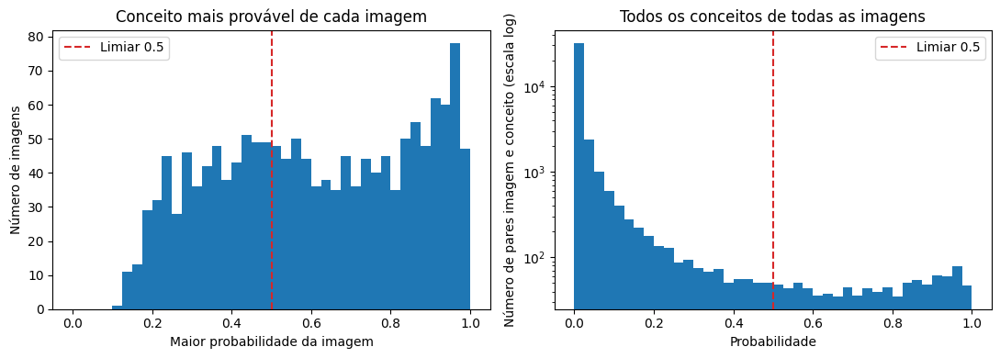

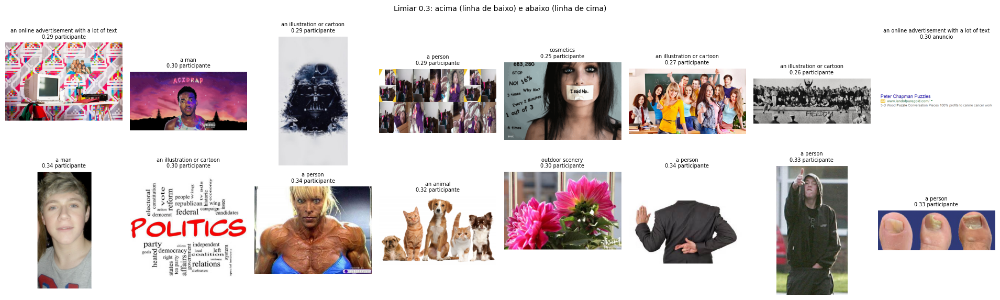

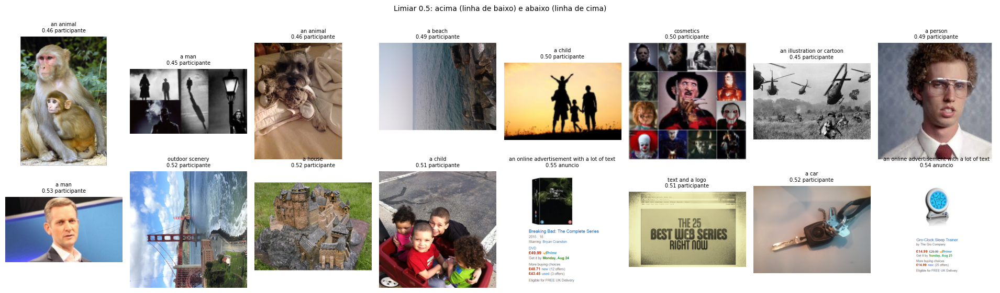

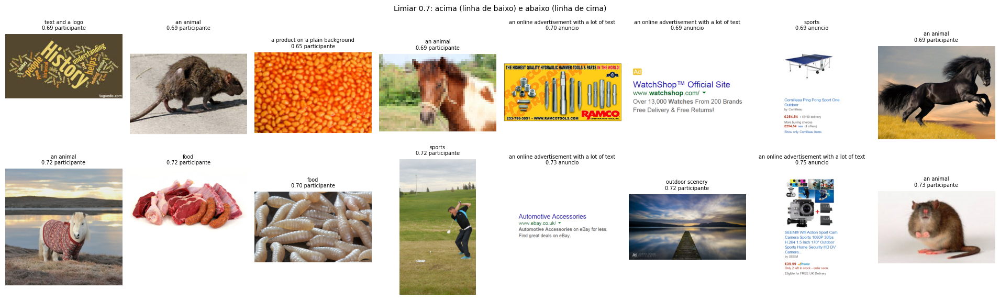

In [ ]:
probabilities = concept_probabilities(similarity, LOGIT_SCALE)
top_probability, top_concept = probabilities.max(dim=1)
distribution_figure = plot_probability_distributions(
    top_probability, probabilities, THRESHOLD, run.figures_dir / "distribution.png"
)

probability_quantiles = {
    str(level): round(top_probability.quantile(level).item(), 3) for level in (0.05, 0.25, 0.5, 0.75, 0.95)
}
print("quantis da probabilidade mais alta por imagem:", probability_quantiles)
share_above = {}
for candidate in CANDIDATE_THRESHOLDS:
    share_above[str(candidate)] = round((top_probability >= candidate).float().mean().item(), 4)
    print(f"limiar {candidate}: {share_above[str(candidate)]:.1%} das imagens têm algum conceito com probabilidade igual ou maior")

threshold_samples = {}
threshold_figures = []
for candidate in CANDIDATE_THRESHOLDS:
    below = sample_in_band(top_probability, candidate - BAND_HALF_WIDTH, candidate, SAMPLES_PER_SIDE, SEED)
    above = sample_in_band(top_probability, candidate, candidate + BAND_HALF_WIDTH, SAMPLES_PER_SIDE, SEED)
    chosen = below + above
    threshold_samples[str(candidate)] = {"below": below, "above": above}
    threshold_figures.append(
        plot_image_grid(
            [image_paths[i] for i in chosen],
            [f"{CONCEPTS[top_concept[i]]}\n{top_probability[i]:.2f} {sources[i]}" for i in chosen],
            f"Limiar {candidate}: acima (linha de baixo) e abaixo (linha de cima)",
            run.figures_dir / f"threshold_{int(candidate * 100):03d}.png",
            columns=SAMPLES_PER_SIDE,
        )
    )
    print(f"limiar {candidate}: abaixo {below}, acima {above}")


## Ranking de conceitos

- Limiar usado: 0,5. A justificativa está na leitura dos resultados, no fim do notebook
- Para cada conceito: similaridade média, probabilidade média, frequência (parcela das imagens em que ele está presente) e contagem
- A ordem é pela frequência e, em caso de empate, pela similaridade média
- O ranking sai para o corpus inteiro, só para os anúncios e só para as imagens dos participantes
- Depois, os cinco conceitos mais frequentes do corpus, cada um com as seis imagens de maior similaridade

ranking: corpus (1501 imagens), limiar 0.5
 1. a photo of an online advertisement with a lot of text: frequência 0.155, contagem 232, similaridade média 0.209
 2. a photo of an animal: frequência 0.080, contagem 120, similaridade média 0.202
 3. a photo of food: frequência 0.061, contagem 92, similaridade média 0.195
 4. a photo of outdoor scenery: frequência 0.049, contagem 73, similaridade média 0.189
 5. a photo of text and a logo: frequência 0.030, contagem 45, similaridade média 0.200
 6. a photo of a child: frequência 0.028, contagem 42, similaridade média 0.195
 7. a photo of a product on a plain background: frequência 0.026, contagem 39, similaridade média 0.192
 8. a photo of a man: frequência 0.025, contagem 38, similaridade média 0.196
 9. a photo of sports: frequência 0.025, contagem 37, similaridade média 0.203
10. a photo of an illustration or cartoon: frequência 0.023, contagem 35, similaridade média 0.207
11. a photo of jewellery: frequência 0.012, contagem 18, similari

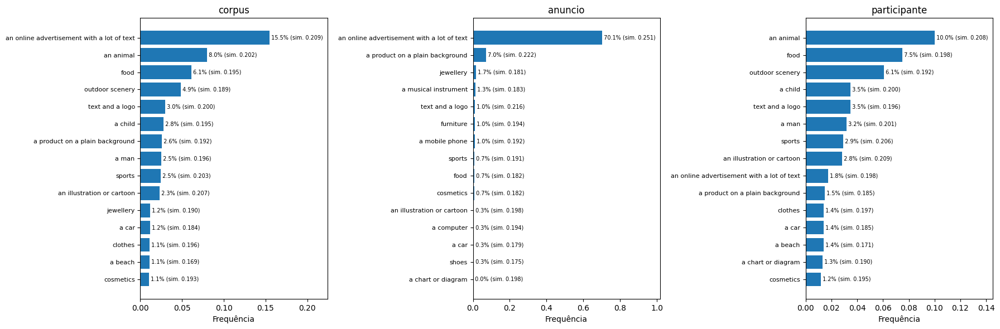

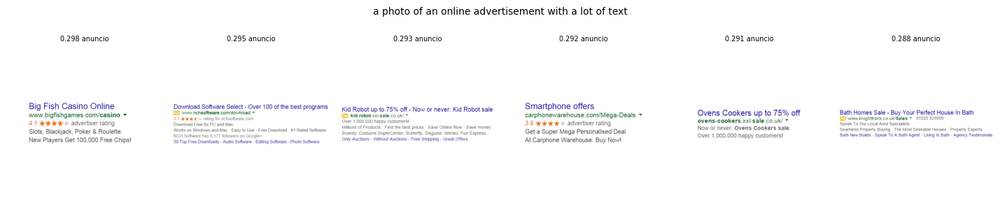

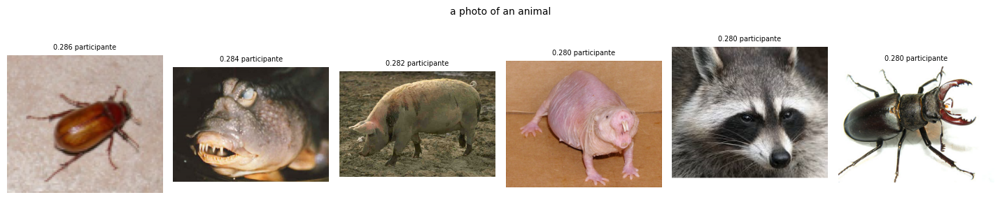

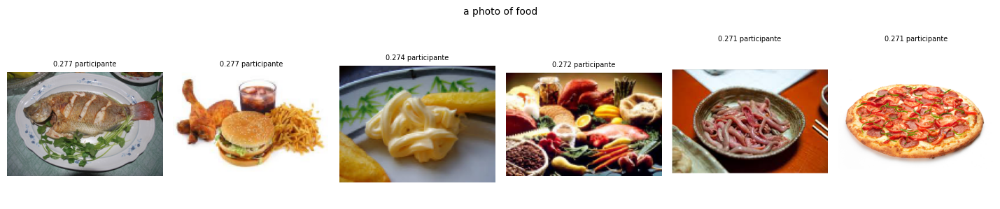

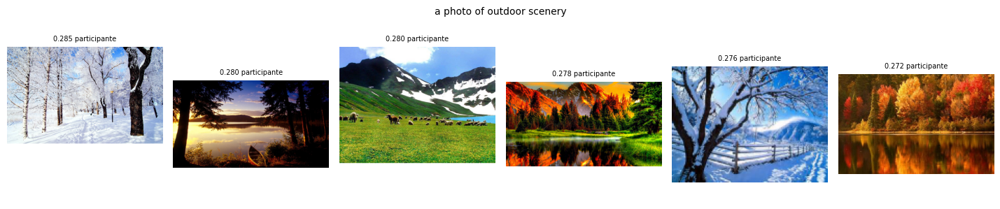

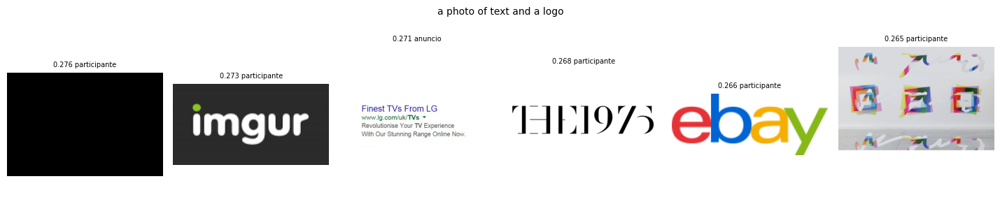

In [ ]:
ranking = {}
for name, indices in source_indices.items():
    ranking[name] = rank_concepts(similarity[indices], PROMPTS, THRESHOLD, LOGIT_SCALE)
    print(f"ranking: {name} ({len(indices)} imagens), limiar {THRESHOLD}")
    for position, row in enumerate(ranking[name], start=1):
        print(
            f"{position:2d}. {row['concept']}: frequência {row['frequency']:.3f}, "
            f"contagem {row['count']}, similaridade média {row['mean_similarity']:.3f}"
        )
ranking_figure = plot_ranking(ranking, run.figures_dir / "ranking.png")

top_examples = {}
top_example_figures = []
for row in ranking["corpus"][:TOP_CONCEPTS]:
    concept_index = PROMPTS.index(row["concept"])
    chosen = top_images(similarity, concept_index, EXAMPLES_PER_CONCEPT)
    top_examples[row["concept"]] = {
        "indices": chosen,
        "scores": [round(similarity[i, concept_index].item(), 4) for i in chosen],
        "sources": [sources[i] for i in chosen],
    }
    top_example_figures.append(
        plot_image_grid(
            [image_paths[i] for i in chosen],
            [f"{similarity[i, concept_index]:.3f} {sources[i]}" for i in chosen],
            row["concept"],
            run.figures_dir / f"top_{len(top_example_figures) + 1}.png",
            columns=EXAMPLES_PER_CONCEPT,
        )
    )


## Busca por texto

- Onze frases, das mais genéricas às mais específicas e das mais concretas às mais abstratas, uma delas em português e outra com muito texto
- As frases foram fixadas antes de ver qualquer resultado e nenhuma foi trocada depois
- A frase vira um vetor com o codificador de texto do CLIP e as imagens mais próximas por similaridade de cosseno são as cinco do resultado
- Cada figura tem a frase como título e a similaridade e a origem sob cada imagem

busca 1: 0.0 s


'a car': [(177, 0.3011, 'participante'), (290, 0.2608, 'participante'), (992, 0.2605, 'participante'), (280, 0.2591, 'participante'), (39, 0.2558, 'anuncio')]
busca 2: 0.0 s


'a red sports car on a road': [(209, 0.2453, 'participante'), (587, 0.2374, 'participante'), (177, 0.2362, 'participante'), (1397, 0.2361, 'participante'), (1262, 0.2349, 'participante')]
busca 3: 0.0 s


'a happy family at home': [(574, 0.2765, 'participante'), (1199, 0.2707, 'participante'), (582, 0.2602, 'participante'), (1150, 0.2538, 'participante'), (414, 0.2515, 'participante')]
busca 4: 0.0 s


'luxury': [(209, 0.2553, 'participante'), (992, 0.2534, 'participante'), (824, 0.2511, 'anuncio'), (1080, 0.2483, 'participante'), (819, 0.2472, 'anuncio')]
busca 5: 0.0 s


'freedom': [(960, 0.2764, 'participante'), (515, 0.2578, 'participante'), (1247, 0.2542, 'participante'), (1334, 0.2497, 'participante'), (267, 0.2483, 'participante')]
busca 6: 0.0 s


'something healthy to eat': [(1007, 0.283, 'participante'), (1420, 0.2786, 'participante'), (1118, 0.2582, 'participante'), (494, 0.2574, 'participante'), (1033, 0.2568, 'participante')]
busca 7: 0.0 s


'technology that makes life easier': [(56, 0.2541, 'anuncio'), (1194, 0.2533, 'participante'), (891, 0.2513, 'anuncio'), (347, 0.2502, 'participante'), (417, 0.25, 'participante')]
busca 8: 0.0 s


'an advertisement with a lot of text': [(892, 0.2819, 'anuncio'), (774, 0.278, 'anuncio'), (771, 0.2714, 'anuncio'), (18, 0.269, 'anuncio'), (893, 0.269, 'anuncio')]
busca 9: 0.0 s


'loneliness': [(1472, 0.2806, 'participante'), (447, 0.2591, 'participante'), (443, 0.2535, 'participante'), (199, 0.2532, 'participante'), (515, 0.2487, 'participante')]
busca 10: 0.0 s


'um cachorro brincando na praia': [(1083, 0.2749, 'participante'), (1162, 0.253, 'participante'), (1047, 0.2483, 'participante'), (301, 0.2481, 'participante'), (920, 0.2443, 'participante')]
busca 11: 0.0 s


'uma pessoa sorrindo': [(1312, 0.2838, 'participante'), (1495, 0.2571, 'participante'), (1074, 0.2537, 'participante'), (974, 0.2455, 'participante'), (399, 0.2416, 'participante')]


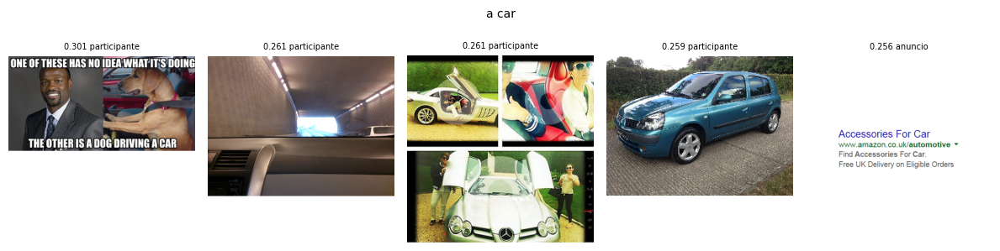

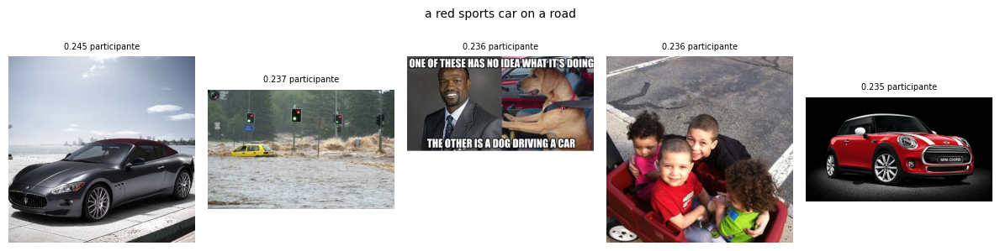

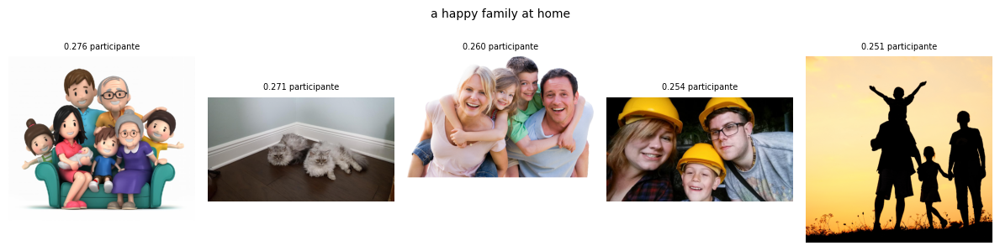

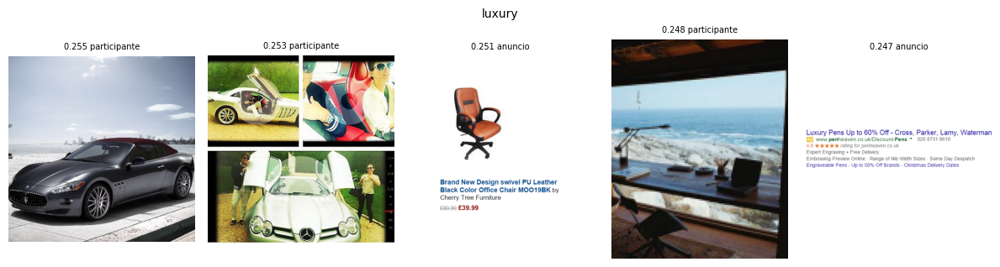

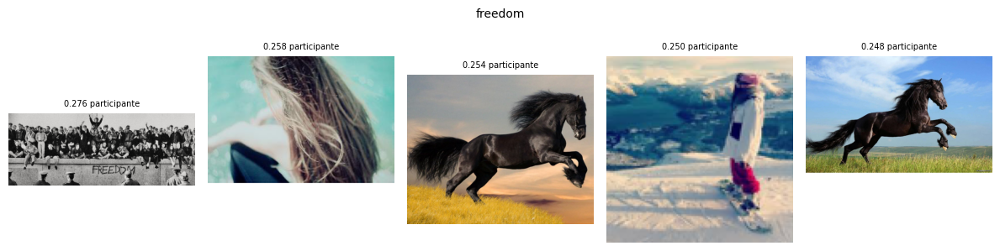

...

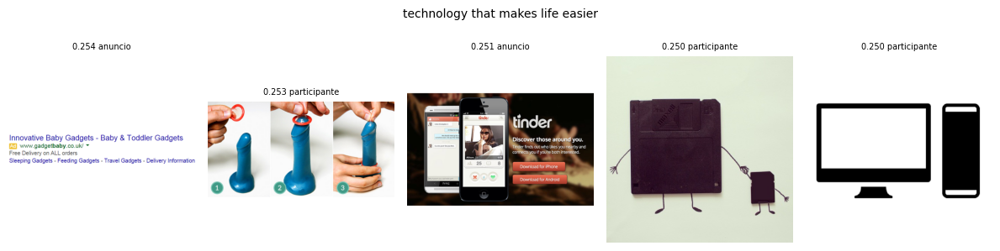

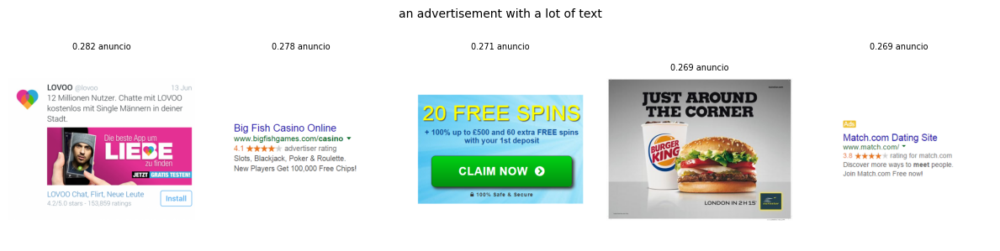

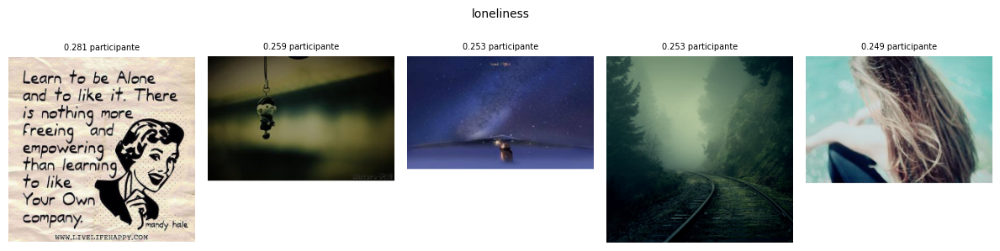

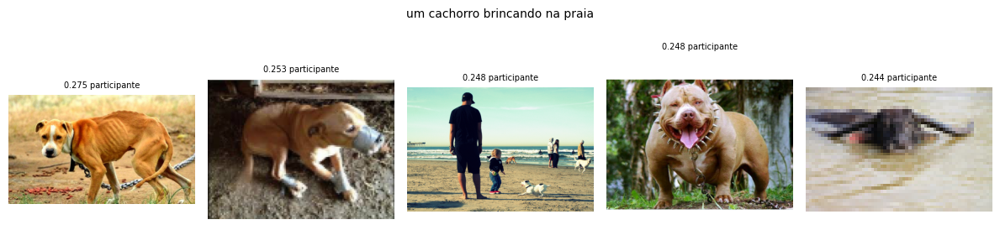

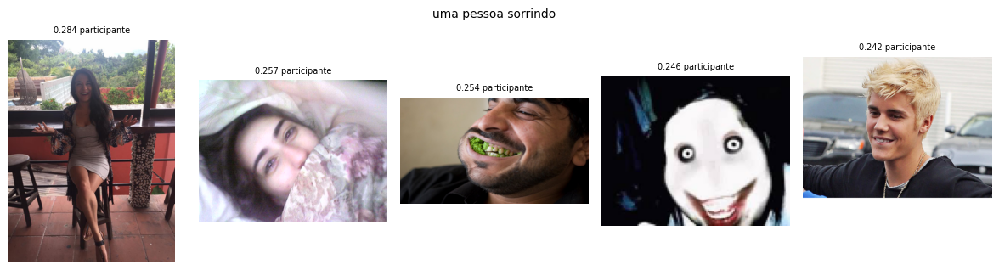

In [ ]:
queries = []
query_figures = []
for number, (query, embedding) in enumerate(zip(QUERIES, query_embeddings), start=1):
    with stopwatch.measure(f"busca {number}"):
        found = search(embedding, image_embeddings, RESULTS_PER_QUERY)
    chosen = [index for index, _ in found]
    queries.append(
        {
            "text": query,
            "results": [
                {"index": index, "score": round(score, 4), "source": sources[index], "file": image_paths[index].name}
                for index, score in found
            ],
        }
    )
    query_figures.append(
        plot_image_grid(
            [image_paths[index] for index in chosen],
            [f"{score:.3f} {sources[index]}" for index, score in found],
            query,
            run.figures_dir / f"query_{number:02d}.png",
            columns=RESULTS_PER_QUERY,
        )
    )
    print(f"{query!r}:", [(row["index"], row["score"], row["source"]) for row in queries[-1]["results"]])


## Tokenização

- Três frases de tamanhos diferentes passam pelo tokenizador do CLIP e pelo do BERT (`bert-base-uncased`)
- O tokenizador completa as frases curtas até o tamanho da mais longa, com preenchimento (padding), e a máscara de atenção marca com 0 as posições de preenchimento
- O CLIP aceita no máximo 77 tokens por texto. Um texto maior é cortado, e o notebook avisa quando isso acontece

In [ ]:
with stopwatch.measure("tokenização"):
    bert_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
    tokenisation = {
        "texts": TOKEN_TEXTS,
        "clip": describe_tokens(processor.tokenizer, TOKEN_TEXTS),
        "bert": describe_tokens(bert_tokenizer, TOKEN_TEXTS),
    }
print("limite de tokens do CLIP:", processor.tokenizer.model_max_length)
for name in ("clip", "bert"):
    for text, described in zip(TOKEN_TEXTS, tokenisation[name]):
        print(f"{name}: {text[:40]!r}: {len(described['tokens'])} posições, {described['padding']} de preenchimento")
        print("  tokens:", described["tokens"])
        print("  máscara de atenção:", described["attention_mask"])


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

tokenização: 1.5 s
limite de tokens do CLIP: 77
clip: 'a car': 27 posições, 23 de preenchimento
  tokens: ['<|startoftext|>', 'a</w>', 'car</w>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>']
  máscara de atenção: [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
clip: 'a red sports car on a road': 27 posições, 18 de preenchimento
  tokens: ['<|startoftext|>', 'a</w>', 'red</w>', 'sports</w>', 'car</w>', 'on</w>', 'a</w>', 'road</w>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>

## Leitura dos resultados

**Corpus**

- O download tem 2.697 arquivos de imagem. Foram removidas 47 cópias exatas, todas entre as imagens dos participantes, e 1.149 miniaturas de imagens que já estão no corpus. Ficaram 1.501 imagens: 301 anúncios e 1.200 imagens de participantes.
- Uma miniatura é um arquivo `<nome>_th_<número>.png` ao lado do arquivo `<nome>.png`, na mesma pasta. Nas 1.173 miniaturas do download, a imagem original existe em todas. Em uma amostra de 200 pares, 197 têm a mesma figura em tamanho menor. Na lista completa, 14 de 1.173 (1,2%) apontam para uma figura diferente, por isso a regra pelo nome remove uma pequena parte de imagens que não eram cópias.
- As miniaturas inflavam as frequências e faziam os resultados da busca virem em pares. Com a remoção, as buscas devolvem cinco imagens diferentes. Resta um par parecido: o brócolis da busca "something healthy to eat" aparece em duas versões, uma delas em resolução baixa, e os nomes dos arquivos não mostram a ligação.
- Os anúncios estão em 20 pastas numeradas, com 15 ou 16 anúncios cada. A atividade fala em 16 categorias, mas o arquivo tem 20 pastas.

**Limiar**

- Limiar usado: 0,5. Um conceito conta como presente quando a sua probabilidade chega a 0,5, isto é, quando ele fica com a maioria da probabilidade entre os 26 conceitos. Por isso cada imagem tem no máximo um conceito presente.
- A distribuição da maior probabilidade por imagem não tem vale nem degrau. Ela é quase plana entre 0,2 e 0,9 e sobe perto de 1. Na distribuição de todas as probabilidades a contagem cai até cerca de 0,4 e depois fica num patamar. Nenhum ponto da curva indica sozinho o limiar.
- Por isso a decisão veio das imagens sorteadas em cada lado dos candidatos. Em 0,3, de 16 imagens, cerca de 10 têm conceito aceitável, com erros como uma moça de fita na boca como cosmético, uma sala colorida e uma turma de alunos como anúncio ou ilustração, e dedos dos pés como pessoa. Em 0,5, cerca de 12 das 16 têm conceito aceitável, com erros como uma colagem de monstros de filmes de terror como cosmético e uma chave como carro. Em 0,7, as 16 têm conceito aceitável.
- A qualidade sobe aos poucos com o limiar e não há um salto. O custo também sobe: com algum conceito presente ficam 86,3% das imagens em 0,3, 62,6% em 0,5 e 40,0% em 0,7. Fiquei com 0,5 por ser o ponto em que a maior parte das imagens inspecionadas já está certa, por manter a maioria do corpus e por dar a regra simples de maioria. Em 0,7 o ranking seria mais limpo, mas 60% das imagens ficariam sem conceito.
- A inspeção usou 8 imagens por lado e por candidato, sorteadas com seed fixa. É uma amostra pequena e a avaliação de cada imagem é minha.

**Ranking**

- Corpus inteiro (1.501 imagens): anúncio online com muito texto (15,5%), animal (8,0%), comida (6,1%), paisagem ao ar livre (4,9%) e texto e logotipo (3,0%). A frequência do anúncio com texto subiu de 9,7% para 15,5% porque as miniaturas saíram só do lado dos participantes e os anúncios passaram a pesar mais no corpus.
- Só anúncios: anúncio online com muito texto em 70,1% (211 de 301), produto sobre fundo liso em 7,0% e depois conceitos com 1,7% ou menos. Os anúncios do corpus são em grande parte banners de texto.
- Só participantes (1.200 imagens): animal (10,0%), comida (7,5%), paisagem (6,1%), criança (3,5%) e texto e logotipo (3,5%). A ordem é a mesma de antes e as frequências mudaram pouco.
- A similaridade média fica entre 0,16 e 0,21 em todos os conceitos do corpus inteiro e quase não separa um conceito do outro. A ordem útil é a da frequência.
- Cerca de 37% das imagens não têm nenhum conceito presente em 0,5. A lista de 26 conceitos não cobre o corpus.
- Os cinco conceitos mais frequentes têm exemplos nas figuras `top_1` a `top_5`. Os de anúncio de texto, animal, comida e paisagem mostram seis imagens diferentes que combinam com o conceito. Em texto e logotipo, um dos seis exemplos é uma imagem totalmente preta, e os outros são logotipos (imgur, THE 1975, eBay), um anúncio de texto e uma arte abstrata.

**Busca por texto**

- Sem as miniaturas, cada busca devolve cinco imagens diferentes. A única exceção é "something healthy to eat", que traz duas fotos do mesmo brócolis, uma em resolução baixa.
- As frases concretas e específicas funcionam melhor: "an advertisement with a lot of text" devolve cinco anúncios com muito texto e "something healthy to eat" devolve frutas, cenouras, uma pirâmide alimentar e brócolis.
- "a car" devolve um meme com um cachorro dentro de um carro, um túnel visto de dentro de um carro, uma colagem de carros esportivos, um carro azul de passeio e um anúncio de texto sobre acessórios para carro. Há carro nas cinco, mas ele é o assunto principal só na colagem e no carro azul.
- Em "a red sports car on a road" só um dos cinco é vermelho, um Mini Cooper, e nenhum é esportivo e vermelho ao mesmo tempo. Os outros são um cupê cinza, um carro amarelo numa enchente, o meme do cachorro no carro e crianças num carrinho vermelho.
- "a happy family at home" devolve uma família de desenho 3D, dois gatos em um canto, uma família real sobre fundo branco, uma mulher, um homem e uma criança de capacete e uma família em silhueta ao pôr do sol. Quatro dos cinco são famílias, nenhuma em casa.
- As frases abstratas dão resultados fracos ou ambíguos. "freedom" traz uma foto com a palavra pichada no muro, cabelo ao vento, dois cavalos diferentes e um snowboarder. "loneliness" traz uma frase escrita sobre ficar sozinho, um boneco pendurado, um céu estrelado, uma ferrovia na névoa e cabelo ao vento. "luxury" traz um carro esportivo, uma colagem de carros, um anúncio de cadeira de escritório, uma mesa diante do mar e um anúncio de canetas de luxo. "technology that makes life easier" traz anúncios de gadgets e de aplicativo, um disquete desenhado, um ícone de computador e uma imagem sem relação com a frase.
- Em português, "uma pessoa sorrindo" devolve pessoas, a maioria sorrindo, e "um cachorro brincando na praia" devolve cachorros. Só uma das imagens tem cachorros numa praia, e ela mostra um homem, uma criança e cachorros. As outras mostram cachorros presos, amarrados ou em posição de ataque. O CLIP entendeu o assunto principal e só às vezes a cena.
- As pontuações ficam entre 0,23 e 0,30.

**Tokenização**

- As três frases têm 4, 9 e 27 posições no CLIP, e o mesmo número no BERT. Com padding até a mais longa, a mais curta tem 23 posições de preenchimento e a máscara de atenção tem 0 nelas.
- O CLIP usa o mesmo símbolo de fim de texto como preenchimento. O BERT usa `[PAD]`.

**Limites**

- Uma execução, com um modelo, um conjunto de conceitos e um conjunto de frases fixados antes de ver os resultados.
- A frequência de cada conceito depende da lista de conceitos, porque a softmax divide a probabilidade entre eles. Outra lista daria outra ordem.

In [ ]:
metrics = {
    "files_found": files_found,
    "duplicates_removed": duplicates_removed,
    "thumbnails_removed": thumbnails_removed,
    "images": len(images),
    "by_source": by_source,
    "ad_categories": ad_categories,
    "concepts": PROMPTS,
    "threshold": {
        "value": THRESHOLD,
        "rule": "um conceito está presente quando a sua probabilidade na softmax entre os conceitos é igual ou maior que o valor",
        "candidates": CANDIDATE_THRESHOLDS,
        "share_of_images_above": share_above,
        "top_probability_quantiles": probability_quantiles,
        "samples": threshold_samples,
    },
    "ranking": ranking,
    "top_examples": top_examples,
    "queries": queries,
    "tokenisation": tokenisation,
    "embedding_seconds": embedding_seconds,
    "step_seconds": stopwatch.seconds,
    "model": "openai/clip-vit-base-patch32",
    "logit_scale": LOGIT_SCALE,
    "seed": SEED,
}
archive = save_run(run, metrics)
saved = json.loads((run.output_dir / "metrics.json").read_text(encoding="utf-8"))
print("arquivo de saída:", archive)
print("tempo total (s):", saved["runtime_seconds"])
print("pico de memória de GPU (MB):", saved["peak_gpu_memory_mb"])
print("pico de memória RAM (MB):", saved["peak_ram_mb"])


arquivo de saída: outputs_a2.zip
tempo total (s): 164.5
pico de memória de GPU (MB): 812.2
pico de memória RAM (MB): 2265.3
